# Air vs Ocean for a Perishable Product: Cost, Carbon, and Shipping Plan

**Business question:** A Kenyan rose grower ships cut flowers to Europe by air. Ocean reefer containers are slower but far cheaper per kilogram. **Can ocean freight compete on cost, how much carbon does it save, and what shipping plan would let the grower use it without missing the Valentine's Day peak?**

Inputs are the case figures from *Sian Flowers: Fresher by Sea?* (UBC Sauder MBA, Supply Chain Management). I turned my written case analysis into a reusable model: cost and CO2 per stem by mode, the air-freight rate at which ocean breaks even, and a comparison of shipping plans.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

STEMS_PER_BOX, BOX_KG, PACKAGING = 350, 17, 6.00          # stems/box, kg/box, $/box
AIR_RATES = {"Air (pre-pandemic)": 1.00, "Air (typical)": 2.65, "Air (peak season)": 5.00}   # $/kg
REEFER, INSURANCE, BOXES_PER_CONTAINER, OCEAN_TREATMENT = 15_000, 600, 540, 0.0214   # $, $, boxes, $/stem
CO2_G_PER_TKM = {"Air": 665, "Ocean": 8}
DISTANCE_KM = {"Air": 6_662, "Ocean": 3_165 + 11_168}
TONNES_PER_STEM = BOX_KG / STEMS_PER_BOX / 1000

def air_cost_per_stem(rate):
    return (BOX_KG * rate + PACKAGING) / STEMS_PER_BOX

ocean_cost = ((REEFER + INSURANCE) / BOXES_PER_CONTAINER + PACKAGING) / STEMS_PER_BOX + OCEAN_TREATMENT
co2 = {m: CO2_G_PER_TKM[m] * DISTANCE_KM[m] * TONNES_PER_STEM for m in CO2_G_PER_TKM}

table = pd.DataFrame(
    [{"Mode": k, "Cost per stem ($)": air_cost_per_stem(r), "CO2 per stem (g)": co2["Air"]} for k, r in AIR_RATES.items()]
    + [{"Mode": "Ocean (reefer)", "Cost per stem ($)": ocean_cost, "CO2 per stem (g)": co2["Ocean"]}]
).set_index("Mode")
print(table.round(3).to_string())

breakeven = (ocean_cost * STEMS_PER_BOX - PACKAGING) / BOX_KG
print(f"\nOcean is cheaper whenever air freight costs more than ${breakeven:.2f}/kg")
print(f"Ocean vs typical air: {ocean_cost / air_cost_per_stem(2.65) - 1:+.0%} cost, {co2['Ocean'] / co2['Air']:.1%} of the CO2")

                    Cost per stem ($)  CO2 per stem (g)
Mode                                                   
Air (pre-pandemic)              0.066           215.183
Air (typical)                   0.146           215.183
Air (peak season)               0.260           215.183
Ocean (reefer)                  0.121             5.569

Ocean is cheaper whenever air freight costs more than $2.14/kg
Ocean vs typical air: -17% cost, 2.6% of the CO2


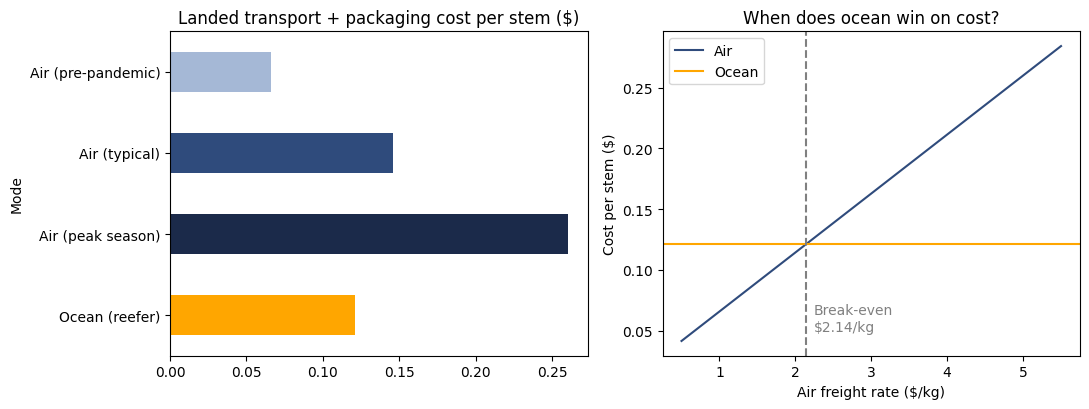

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
colors = ["#a5b8d6", "#2f4b7c", "#1b2a4a", "#ffa600"]
table["Cost per stem ($)"].plot(kind="barh", ax=axes[0], color=colors)
axes[0].set_title("Landed transport + packaging cost per stem ($)")
axes[0].invert_yaxis()
rates = np.linspace(0.5, 5.5, 50)
axes[1].plot(rates, [air_cost_per_stem(r) for r in rates], color="#2f4b7c", label="Air")
axes[1].axhline(ocean_cost, color="#ffa600", label="Ocean")
axes[1].axvline(breakeven, color="grey", ls="--")
axes[1].text(breakeven + 0.1, 0.05, f"Break-even\n${breakeven:.2f}/kg", color="grey")
axes[1].set_xlabel("Air freight rate ($/kg)"); axes[1].set_ylabel("Cost per stem ($)")
axes[1].set_title("When does ocean win on cost?"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/cost_and_breakeven.png", dpi=150); plt.show()

## Shipping plan: level ocean flow vs hybrid

Annual demand is 120 million stems: 9 million a month, plus a February spike to 21 million. Ocean transit is long, so the grower has two realistic options:
1. **Level ocean plan:** ship 10 million stems every month by sea and build inventory ahead of February.
2. **Hybrid plan:** ship base demand (9 million a month) by sea and fly the 12-million February surplus at peak air rates.

                                Freight + packaging ($M)  CO2 (tonnes)  Peak inventory held (M stems)
Plan                                                                                                 
Level ocean                                        14.53        668.33                             11
Hybrid (ocean base + air peak)                     16.20       3183.69                              0


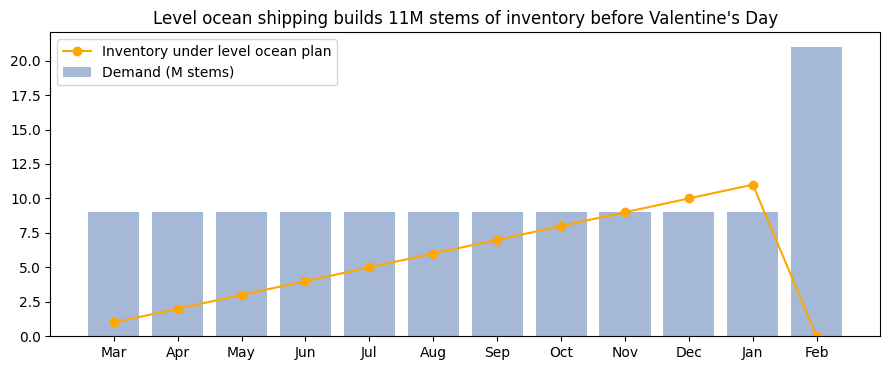

In [3]:
months = ["Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec","Jan","Feb"]
demand = np.array([9] * 11 + [21])                       # millions of stems
level_ship = np.full(12, 10)
level_inventory = np.cumsum(level_ship - demand)

plans = {
    "Level ocean": {"ocean": 120, "air": 0, "peak_inventory": level_inventory.max()},
    "Hybrid (ocean base + air peak)": {"ocean": 108, "air": 12, "peak_inventory": 0},
}
rows = []
for name, p in plans.items():
    cost = (p["ocean"] * ocean_cost + p["air"] * air_cost_per_stem(AIR_RATES["Air (peak season)"])) * 1e6
    carbon_t = (p["ocean"] * co2["Ocean"] + p["air"] * co2["Air"]) * 1e6 / 1e6     # tonnes
    rows.append({"Plan": name, "Freight + packaging ($M)": cost / 1e6, "CO2 (tonnes)": carbon_t,
                 "Peak inventory held (M stems)": p["peak_inventory"]})
plan_table = pd.DataFrame(rows).set_index("Plan")
print(plan_table.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(months, demand, color="#a5b8d6", label="Demand (M stems)")
ax.plot(months, level_inventory, color="#ffa600", marker="o", label="Inventory under level ocean plan")
ax.set_title("Level ocean shipping builds 11M stems of inventory before Valentine's Day")
ax.legend(); plt.tight_layout(); plt.savefig("images/shipping_plan.png", dpi=150); plt.show()

## Findings

- **Ocean wins on cost whenever air costs more than about $2.14/kg**, which has been true since the pandemic: at the typical $2.65/kg it is about 17% cheaper per stem, and far cheaper at peak-season rates.
- **Ocean cuts transport CO2 by about 97%** (about 5.6 g vs 216 g per stem), a strong sustainability story for European retailers.
- **The level ocean plan is the cheapest and lowest-carbon**, but it means holding up to 11 million stems in cold storage before February, which is a shelf-life and working-capital risk this model does not price.
- **The trade-off is explicit:** the hybrid plan avoids the 11-million-stem inventory build but costs about **$1.7M more** in freight and adds about **2,500 tonnes of CO2**. It is worth it only if cold-storage cost and shelf-life losses on the level plan would exceed that.
- **Recommendation:** default to ocean for base demand, pilot a partial pre-build for February, and price cold-storage and spoilage before committing to a fully level plan. That is the next data point this model needs.

**Skills shown:** landed-cost modelling, break-even analysis, carbon accounting (g CO2 per tonne-km), level vs chase production planning, inventory profiling.